In [ ]:
from pathlib import Path
import pandas as pd

# Locate the project and reports folder
PROJECT_ROOT = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)
REPORTS_DIR = PROJECT_ROOT / "reports"

# Load results from Notebook 02 and Notebook 03
files = {
    "backtest_comparison": "backtest_comparison.csv",
    "robustness_results": "robustness_results.csv",
    "transaction_cost_analysis": "transaction_cost_analysis.csv",
    "strategy_dependency_analysis": "strategy_dependency_analysis.csv",
    "ml_evaluation": "ml_evaluation.csv",
    "ml_performance": "ml_performance.csv",
    "ml_coefficients": "ml_coefficients.csv",
    "ml_yearly_performance": "ml_yearly_performance.csv",
}

results = {}

for name, filename in files.items():
    path = REPORTS_DIR / filename

    if not path.exists():
        raise FileNotFoundError(f"Missing results file: {path}")

    results[name] = pd.read_csv(path, index_col=0)
    print(f"{name}: {results[name].shape}")

print("\nAll experiment result files loaded successfully.")

In [ ]:
# Display the main research findings

print("=" * 60)
print("1. BACKTEST COMPARISON")
print("=" * 60)
display(results["backtest_comparison"])

print("\n" + "=" * 60)
print("2. MACHINE LEARNING EVALUATION")
print("=" * 60)
display(results["ml_evaluation"])

print("\n" + "=" * 60)
print("3. MACHINE LEARNING STRATEGY PERFORMANCE")
print("=" * 60)
display(results["ml_performance"])

print("\n" + "=" * 60)
print("4. TRANSACTION COST ANALYSIS")
print("=" * 60)
display(results["transaction_cost_analysis"])

print("\n" + "=" * 60)
print("5. ROBUSTNESS TESTS")
print("=" * 60)
display(results["robustness_results"])

In [ ]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Locate the project reports folder
PROJECT_ROOT = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)
OUTPUT_DIR = PROJECT_ROOT / "reports"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Reuse results already exported from Notebooks 02 and 03
file_mapping = {
    "ml_model_coefficients.csv": "ml_coefficients.csv",
    "ml_yearly_performance.csv": "ml_yearly_performance.csv",
    "ml_prediction_metrics.csv": "ml_evaluation.csv",
    "ml_strategy_vs_benchmark.csv": "ml_performance.csv",
    "transaction_cost_stress_test.csv": "transaction_cost_analysis.csv",
    "best_day_dependency_test.csv": "strategy_dependency_analysis.csv",
}

for output_name, source_name in file_mapping.items():
    source_path = OUTPUT_DIR / source_name

    if not source_path.exists():
        raise FileNotFoundError(
            f"Missing file: {source_path}"
        )

    df = pd.read_csv(source_path)
    df.to_csv(OUTPUT_DIR / output_name, index=False)
    print(f"Saved: {output_name}")

# Save the ML strategy chart from the existing performance data
strategy_data = pd.read_csv(OUTPUT_DIR / "ml_performance.csv", index_col=0)

print("\nExisting ML performance table:")
print(strategy_data.to_string())

print("\nExisting report files:")
for file in sorted(OUTPUT_DIR.iterdir()):
    if file.is_file():
        print("-", file.name)


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_ROOT = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)
OUTPUT_DIR = PROJECT_ROOT / "reports"

# Load the actual out-of-sample ML strategy data
strategy = pd.read_csv(
    OUTPUT_DIR / "ml_strategy_vs_benchmark.csv"
)

print("Available columns:")
print(strategy.columns.tolist())

print("\nPreview:")
display(strategy.head())


In [ ]:

from pathlib import Path

PROJECT_ROOT = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)
OUTPUT_DIR = PROJECT_ROOT / "reports"

print("Files currently in reports/:")
for file in sorted(OUTPUT_DIR.iterdir()):
    if file.is_file():
        print(file.name)


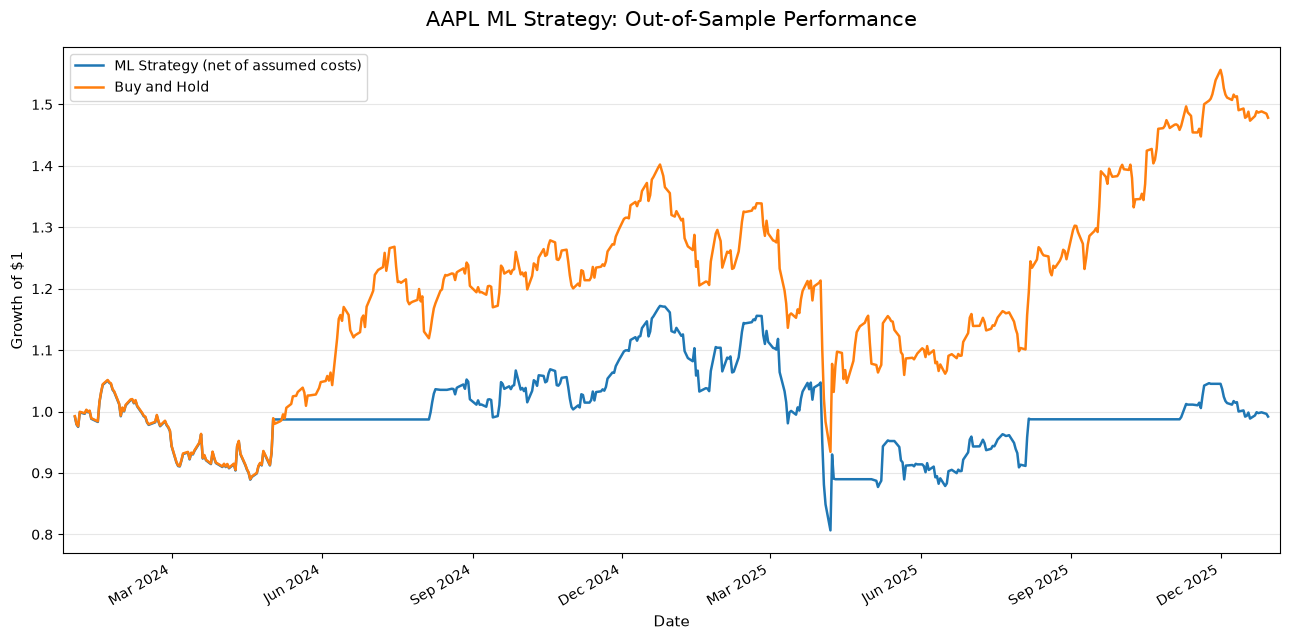

Chart saved to: /Users/ashwinrajesh/Documents/PROJECTS/ai-quant-research-lab/reports/ml_strategy_performance.png


In [1]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

PROJECT_ROOT = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)
OUTPUT_DIR = PROJECT_ROOT / "reports"

# Load actual daily out-of-sample returns
daily_strategy = pd.read_csv(
    OUTPUT_DIR / "ml_daily_strategy_returns.csv",
    index_col=0
)

# Convert index into actual dates
daily_strategy.index = pd.to_datetime(
    daily_strategy.index,
    errors="raise"
)

daily_strategy = daily_strategy.sort_index()

# Calculate cumulative growth of $1
ml_equity = (1 + daily_strategy["Strategy_Return"]).cumprod()
buy_hold_equity = (1 + daily_strategy["Buy_Hold_Return"]).cumprod()

# Create chart
fig, ax = plt.subplots(figsize=(13, 6.5))

ax.plot(
    ml_equity.index,
    ml_equity,
    label="ML Strategy (net of assumed costs)",
    linewidth=1.8
)

ax.plot(
    buy_hold_equity.index,
    buy_hold_equity,
    label="Buy and Hold",
    linewidth=1.8
)

# Titles and labels
ax.set_title(
    "AAPL ML Strategy: Out-of-Sample Performance",
    fontsize=15,
    pad=15
)
ax.set_xlabel("Date", fontsize=11)
ax.set_ylabel("Growth of $1", fontsize=11)

# Display quarterly date ticks
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

fig.autofmt_xdate(rotation=30, ha="right")

# Formatting
ax.legend(loc="upper left", frameon=True)
ax.grid(True, axis="y", alpha=0.3)
ax.margins(x=0.01)

fig.tight_layout()

# Save chart
chart_path = OUTPUT_DIR / "ml_strategy_performance.png"

fig.savefig(
    chart_path,
    dpi=250,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Chart saved to:", chart_path.resolve())


In [ ]:

from pathlib import Path

PROJECT_ROOT = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)
OUTPUT_DIR = PROJECT_ROOT / "reports"

print("FINAL RESEARCH OUTPUTS")
print("=" * 40)

for file in sorted(OUTPUT_DIR.iterdir()):
    if file.is_file():
        print(f"{file.name} ({file.stat().st_size:,} bytes)")


In [12]:

from pathlib import Path
import pandas as pd
from datetime import date

PROJECT_ROOT = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)
OUTPUT_DIR = PROJECT_ROOT / "reports"

# Load actual experimental results
backtest = pd.read_csv(
    OUTPUT_DIR / "backtest_comparison.csv", index_col=0
)
ml_evaluation = pd.read_csv(
    OUTPUT_DIR / "ml_evaluation.csv", index_col=0
)
ml_performance = pd.read_csv(
    OUTPUT_DIR / "ml_performance.csv", index_col=0
)
costs = pd.read_csv(
    OUTPUT_DIR / "transaction_cost_analysis.csv"
)
robustness = pd.read_csv(
    OUTPUT_DIR / "robustness_results.csv"
)

def markdown_table(df):
    return df.to_markdown()

report = f"""# AI Quant Research Lab
## Research Report: Strategy Testing and Falsification

**Generated:** {date.today().isoformat()}

## 1. Research objective

This project evaluates whether systematic trading signals and a machine-learning
model can produce useful out-of-sample results after accounting for risk and
assumed transaction costs. The research compares strategies with Buy and Hold
and examines sensitivity to model and trading assumptions.

## 2. Moving-average strategy: backtest comparison

{markdown_table(backtest)}

The moving-average strategy produced a lower total return than Buy and Hold in
the reported comparison. It also had lower annualized volatility and a smaller
maximum drawdown. Its Sharpe ratio was slightly lower, so the strategy did not
improve every measure of risk-adjusted performance.

## 3. Machine-learning prediction evaluation

{markdown_table(ml_evaluation)}

The Logistic Regression model achieved 47.3% accuracy and a ROC AUC of
approximately 0.466. It did not demonstrate convincing predictive skill on
this test set. Its accuracy was below the simple majority-class baseline, which
is an important warning against assuming that a trained model has predictive
value simply because it produces predictions.

## 4. Machine-learning strategy performance

{markdown_table(ml_performance)}

The ML strategy underperformed Buy and Hold on total return, CAGR, and Sharpe
ratio in the reported out-of-sample comparison. Its maximum drawdown was also
slightly smaller in magnitude, but that alone does not compensate for its weak
return and Sharpe results.

![ML strategy out-of-sample performance](ml_strategy_performance.png)

## 5. Transaction-cost sensitivity

{markdown_table(costs)}

Performance weakened as the assumed one-way transaction cost increased. This
shows why transaction costs must be included in backtests rather than judging a
strategy using gross returns alone.

## 6. Moving-average robustness tests

{markdown_table(robustness)}

Results varied across moving-average parameter choices. The best-performing
parameter combination in this table should not automatically be treated as
the best future strategy: selecting parameters after examining the same
historical period can introduce selection bias.

## 7. Limitations

- Historical performance does not guarantee future performance.
- The results depend on the chosen asset, test period, features, and assumptions.
- The ML model's weak evaluation metrics do not support a claim of reliable
  directional prediction.
- Transaction-cost estimates may not capture all slippage, liquidity, and
  execution effects.
- Further work should use strict walk-forward validation, realistic execution
  assumptions, and controls for data leakage and repeated strategy selection.

## 8. Conclusion

The experiments illustrate the importance of trying to falsify trading
strategies rather than accepting attractive historical results at face value.
The moving-average strategy's results were sensitive to assumptions and did
not consistently beat Buy and Hold. The ML experiment performed poorly against
its benchmark and simple prediction baselines.

**Current research verdict:** the tested ML approach is not supported as a
profitable trading strategy by these results. The next step is not to deploy it,
but to investigate the causes of weak predictive performance and evaluate
carefully designed alternatives on genuinely unseen data.
"""

report_path = OUTPUT_DIR / "final_research_report.md"
report_path.write_text(report, encoding="utf-8")

print("Final report saved to:", report_path.resolve())
print("Report size:", report_path.stat().st_size, "bytes")


Final report saved to: /Users/ashwinrajesh/Documents/PROJECTS/ai-quant-research-lab/reports/final_research_report.md
Report size: 6502 bytes


In [11]:
%pip install tabulate


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

PROJECT_ROOT = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

OUTPUT_DIR = PROJECT_ROOT / "reports"

# Load close-execution and open-execution OOS returns
close_data = pd.read_csv(
    OUTPUT_DIR / "aapl_mean_reversion_oos_daily.csv"
)

open_data = pd.read_csv(
    OUTPUT_DIR / "aapl_mean_reversion_open_daily.csv"
)

# Convert dates and sort chronologically
for df in (close_data, open_data):
    df["Date"] = pd.to_datetime(df["Date"])
    df.sort_values("Date", inplace=True)

# Reconstruct equity curves directly from daily returns
close_strategy = (1 + close_data["Net_Return"]).cumprod()
close_benchmark = (1 + close_data["Asset_Return"]).cumprod()

open_strategy = (1 + open_data["Net_Return"]).cumprod()
open_benchmark = (1 + open_data["Asset_Return"]).cumprod()

# Plot all four equity curves
fig, ax = plt.subplots(figsize=(13, 7))

ax.plot(
    close_data["Date"],
    close_strategy,
    label="Mean Reversion — Close Execution",
    linewidth=1.8
)

ax.plot(
    close_data["Date"],
    close_benchmark,
    label="Buy & Hold — Close-to-Close",
    linewidth=1.8,
    linestyle="--"
)

ax.plot(
    open_data["Date"],
    open_strategy,
    label="Mean Reversion — Open Execution",
    linewidth=1.8
)

ax.plot(
    open_data["Date"],
    open_benchmark,
    label="Buy & Hold — Open-to-Open",
    linewidth=1.8,
    linestyle="--"
)

ax.set_title(
    "AAPL Mean-Reversion Strategies: Out-of-Sample Performance",
    fontsize=14,
    pad=15
)

ax.set_xlabel("Date")
ax.set_ylabel("Growth of $1")

ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

ax.grid(True, alpha=0.3)
ax.legend(loc="best", fontsize=9)

fig.autofmt_xdate()
fig.tight_layout()

chart_path = OUTPUT_DIR / "mean_reversion_execution_comparison.png"

fig.savefig(
    chart_path,
    dpi=250,
    bbox_inches="tight"
)

plt.show()

# Verify final cumulative returns
print("FINAL OUT-OF-SAMPLE RETURNS")
print("--------------------------------")
print(f"Close-execution strategy: {(close_strategy.iloc[-1] - 1):.2%}")
print(f"Close-execution benchmark: {(close_benchmark.iloc[-1] - 1):.2%}")
print(f"Open-execution strategy:   {(open_strategy.iloc[-1] - 1):.2%}")
print(f"Open-execution benchmark:  {(open_benchmark.iloc[-1] - 1):.2%}")

print("\nChart saved to:", chart_path.resolve())